# Regression with Decision Tree & Random Forest
## Business case: Predict daily bike rentals
We use the UCI Bike Sharing `day.csv` dataset. Target: `cnt` (daily rental count). We exclude `casual` and `registered` because they sum to `cnt` and would cause target leakage.

Learning goals: understand regression splits, ensemble averaging, model evaluation, residuals, feature importance and overfitting.

## 1. Load data

In [1]:
import io, zipfile, urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/navaneeth20/Aadh/master/Data/day.csv"
df = pd.read_csv(url)
print("Dataset shape:", df.shape)
display(df.head())

#url = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
#with urllib.request.urlopen(url) as r:
    #z = zipfile.ZipFile(io.BytesIO(r.read()))
    #with z.open("day.csv") as f:
        #df = pd.read_csv(f)
print(df.shape)
display(df.head())

Dataset shape: (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


(731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


## 2. Explore the dataset

,count,mean,std,min,25%,50%,75%,max
instant,731.0,366.000000,211.165812,1.000000,183.500000,366.000000,548.500000,731.000000
season,731.0,2.496580,1.110807,1.000000,2.000000,3.000000,3.000000,4.000000
yr,731.0,0.500684,0.500342,0.000000,0.000000,1.000000,1.000000,1.000000
mnth,731.0,6.519836,3.451913,1.000000,4.000000,7.000000,10.000000,12.000000
holiday,731.0,0.028728,0.167155,0.000000,0.000000,0.000000,0.000000,1.000000
weekday,731.0,2.997264,2.004787,0.000000,1.000000,3.000000,5.000000,6.000000
workingday,731.0,0.683995,0.465233,0.000000,0.000000,1.000000,1.000000,1.000000
weathersit,731.0,1.395349,0.544894,1.000000,1.000000,1.000000,2.000000,3.000000
temp,731.0,0.495385,0.183051,0.059130,0.337083,0.498333,0.655417,0.861667
atemp,731.0,0.474354,0.162961,0.079070,0.337842,0.486733,0.608602,0.840896


,missing
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


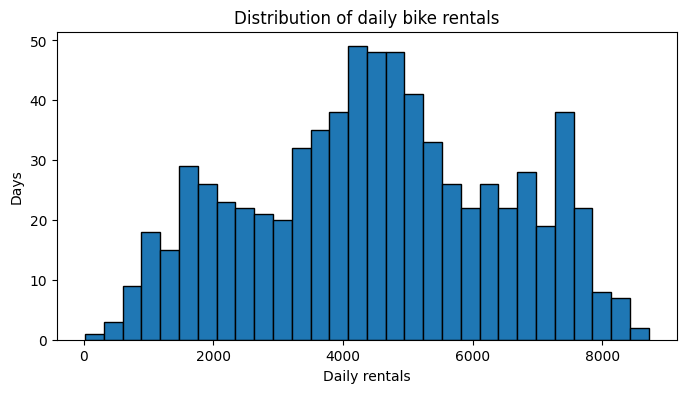

,average_rentals
season,
1,2604.132597
2,4992.331522
3,5644.303191
4,4728.162921


In [2]:
display(df.describe().T)
display(df.isna().sum().to_frame("missing"))
plt.figure(figsize=(8,4))
plt.hist(df["cnt"], bins=30, edgecolor="black")
plt.xlabel("Daily rentals"); plt.ylabel("Days")
plt.title("Distribution of daily bike rentals")
plt.show()

display(df.groupby("season")["cnt"].mean().to_frame("average_rentals"))

## 3. Prepare features and split

In [3]:
from sklearn.model_selection import train_test_split

features = ["season","yr","mnth","holiday","weekday","workingday",
            "weathersit","temp","atemp","hum","windspeed"]
X, y = df[features].copy(), df["cnt"].copy()

# Exclude instant/date identifiers and casual/registered (target leakage).
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (584, 11) Test: (147, 11)


## 4. Train a Decision Tree Regressor

In [4]:
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(
    criterion="squared_error", max_depth=4,
    min_samples_leaf=5, random_state=42
)
dt.fit(X_train, y_train)
print("Decision Tree trained.")

Decision Tree trained.


## 5. Visualize the Decision Tree

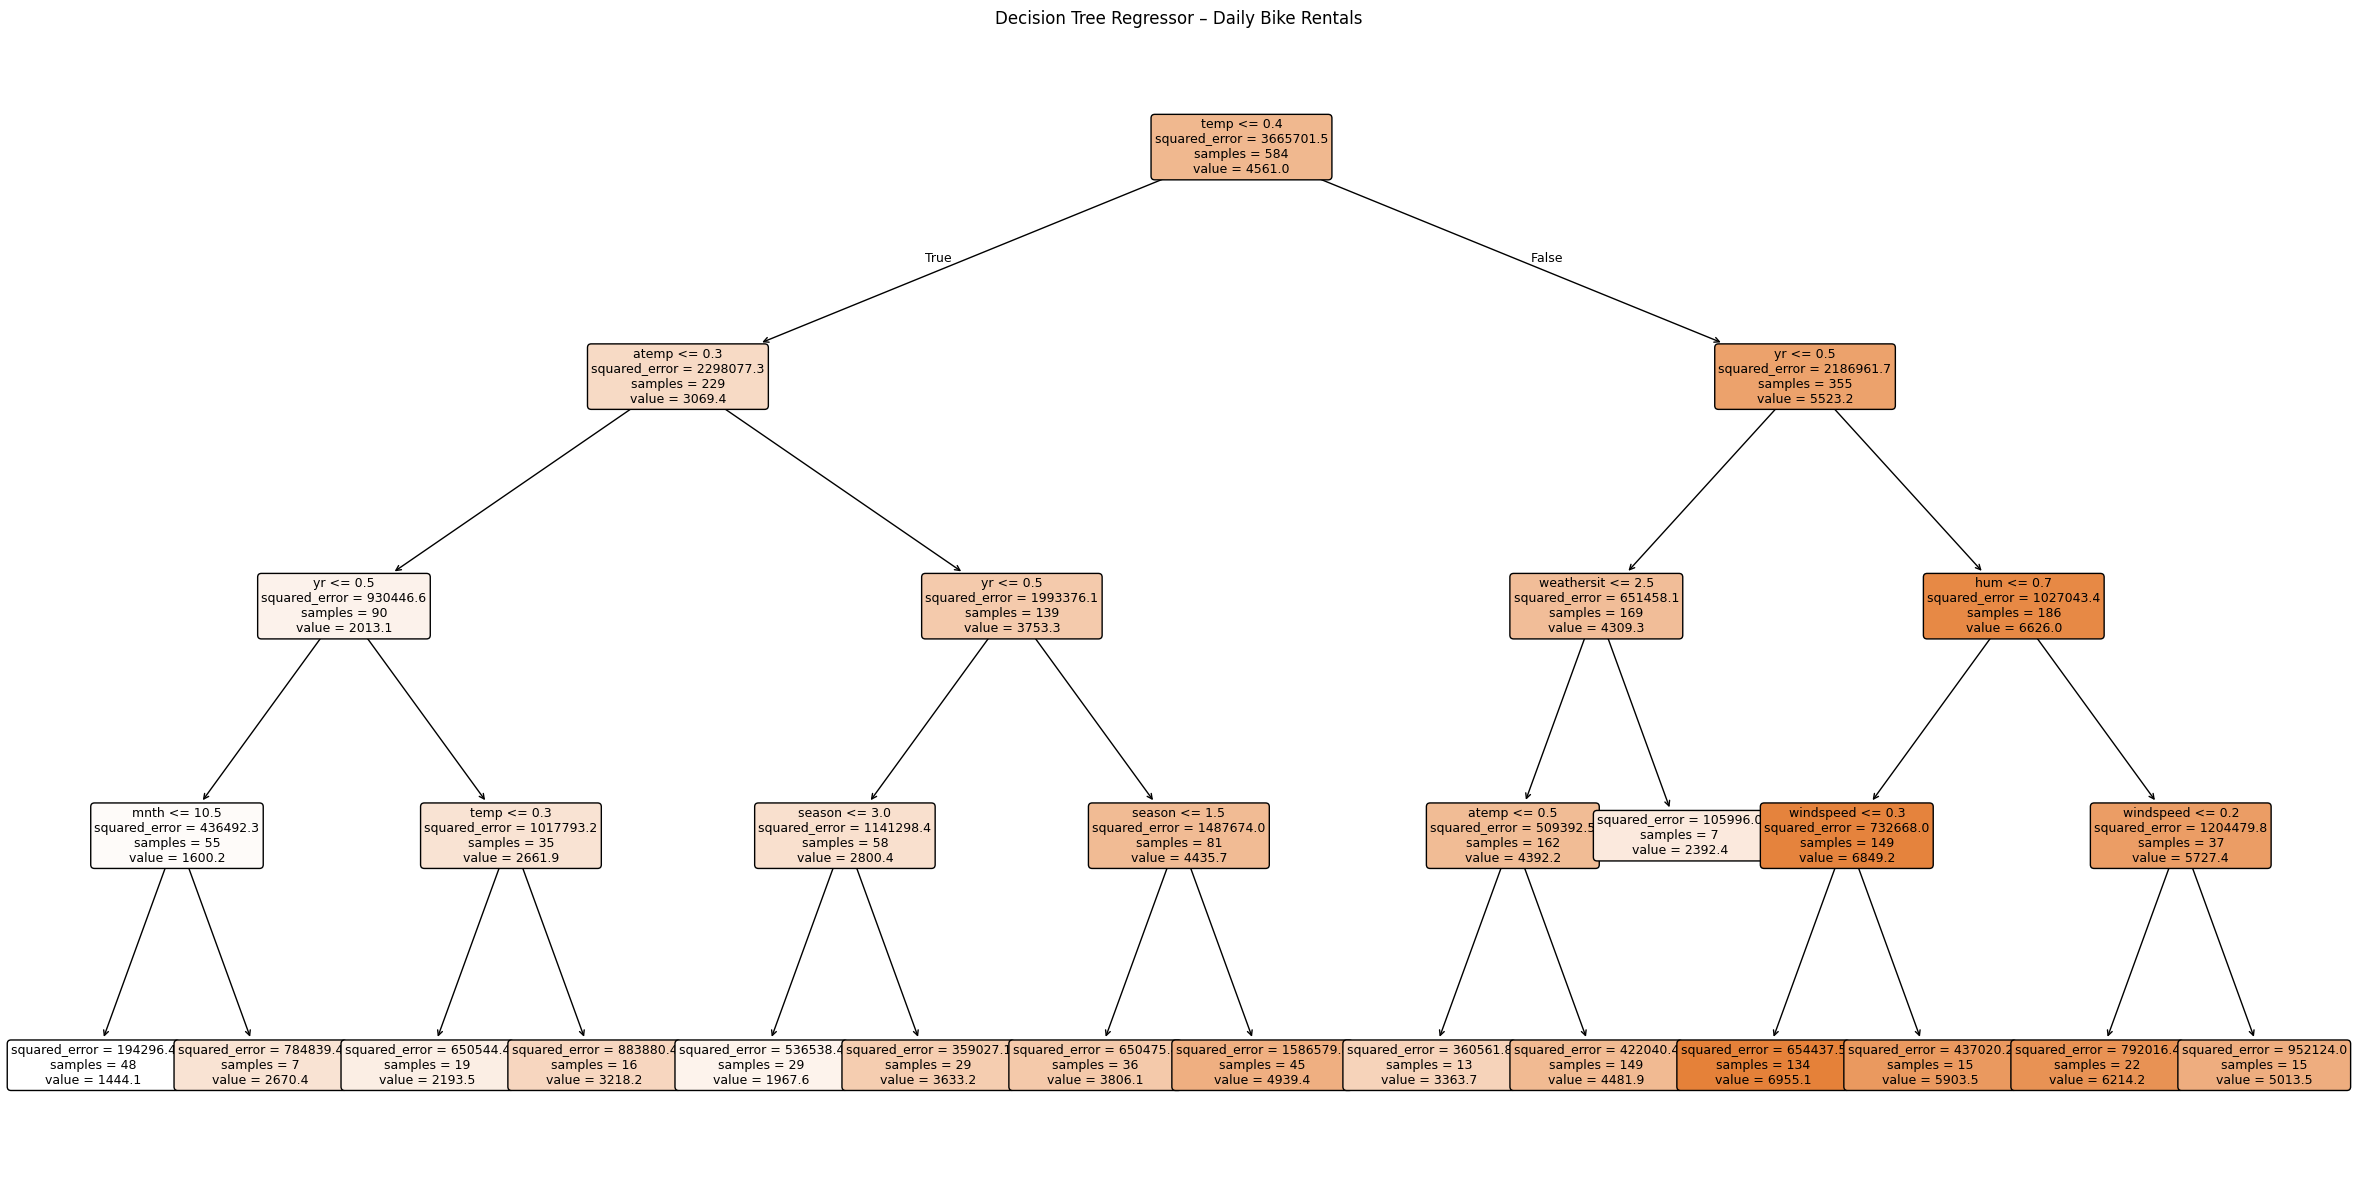

In [5]:
from sklearn.tree import plot_tree

plt.figure(figsize=(24,12))
plot_tree(dt, feature_names=features, filled=True, rounded=True,
          impurity=True, precision=1, fontsize=9)
plt.title("Decision Tree Regressor – Daily Bike Rentals")
plt.tight_layout()
plt.show()

## 6. Train a Random Forest Regressor

In [6]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=300, criterion="squared_error",
    max_features=1.0, max_depth=None, min_samples_leaf=2,
    bootstrap=True, oob_score=True, random_state=42, n_jobs=-1
)
rf.fit(X_train, y_train)
print("Trees:", len(rf.estimators_))
print("OOB R²:", round(rf.oob_score_, 4))

Trees: 300
OOB R²: 0.8712


## 7. Inspect one tree inside the forest

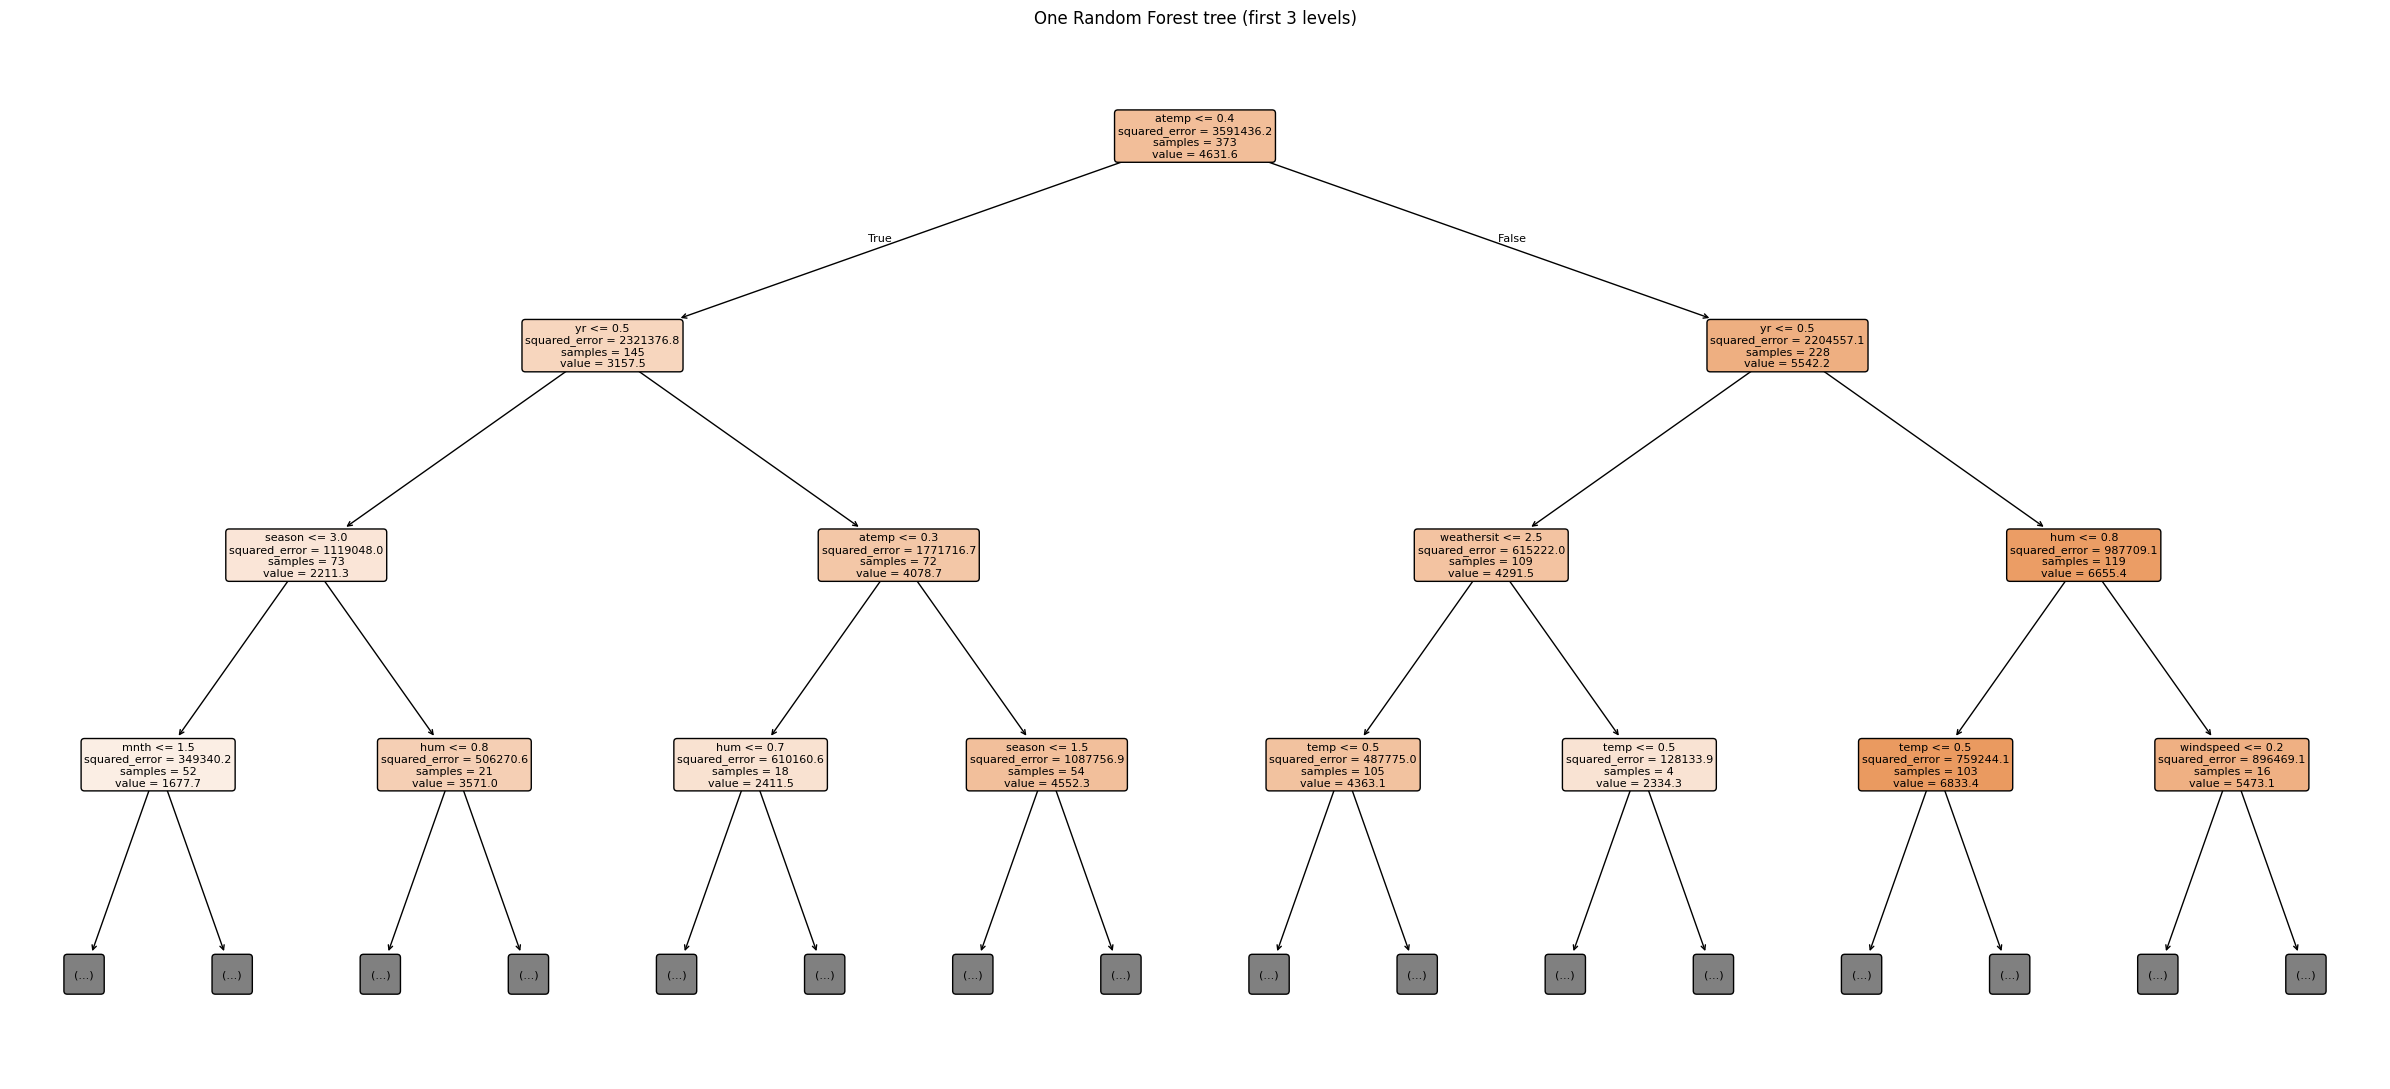

In [7]:
plt.figure(figsize=(24,11))
plot_tree(rf.estimators_[0], feature_names=features, filled=True,
          rounded=True, impurity=True, precision=1,
          max_depth=3, fontsize=8)
plt.title("One Random Forest tree (first 3 levels)")
plt.tight_layout()
plt.show()

## 8. Evaluate both models

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pred_dt = dt.predict(X_test)
pred_rf = rf.predict(X_test)

def metrics(actual, predicted, name):
    mse = mean_squared_error(actual, predicted)
    return {"Model":name, "MAE":mean_absolute_error(actual,predicted),
            "MSE":mse, "RMSE":np.sqrt(mse), "R²":r2_score(actual,predicted)}

results = pd.DataFrame([
    metrics(y_test,pred_dt,"Decision Tree"),
    metrics(y_test,pred_rf,"Random Forest")
])
display(results.round(2))

,Model,MAE,MSE,RMSE,R²
0,Decision Tree,651.65,908426.76,953.11,0.77
1,Random Forest,434.96,476501.67,690.29,0.88


## 9. Actual vs predicted

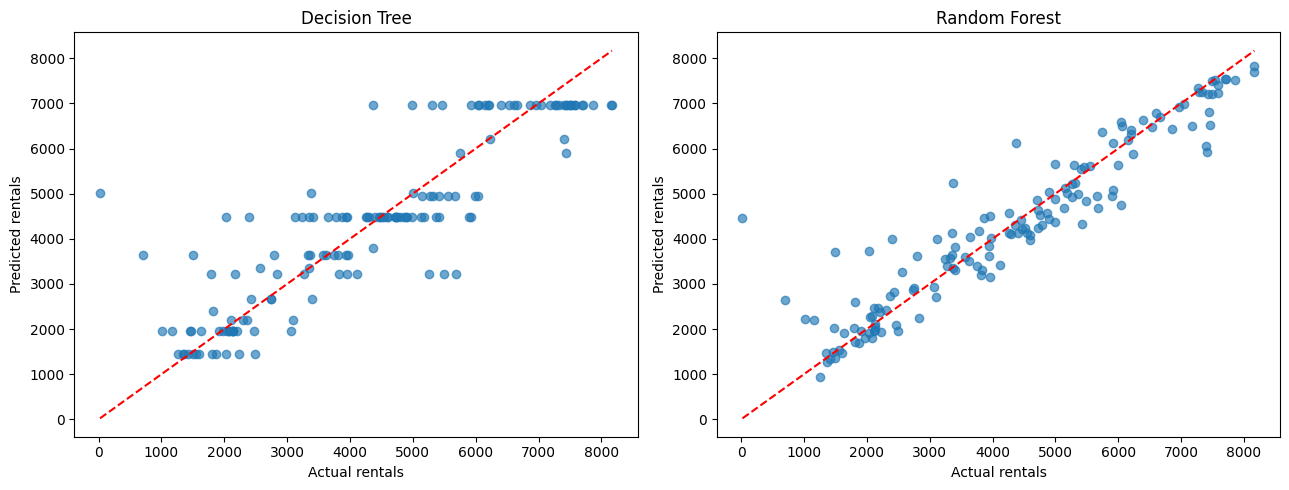

In [9]:
fig, axes = plt.subplots(1,2,figsize=(13,5))
for ax, pred, title in [
    (axes[0],pred_dt,"Decision Tree"),
    (axes[1],pred_rf,"Random Forest")
]:
    ax.scatter(y_test,pred,alpha=.65)
    lo,hi=min(y_test.min(),pred.min()),max(y_test.max(),pred.max())
    ax.plot([lo,hi],[lo,hi],"r--")
    ax.set_xlabel("Actual rentals"); ax.set_ylabel("Predicted rentals")
    ax.set_title(title)
plt.tight_layout(); plt.show()

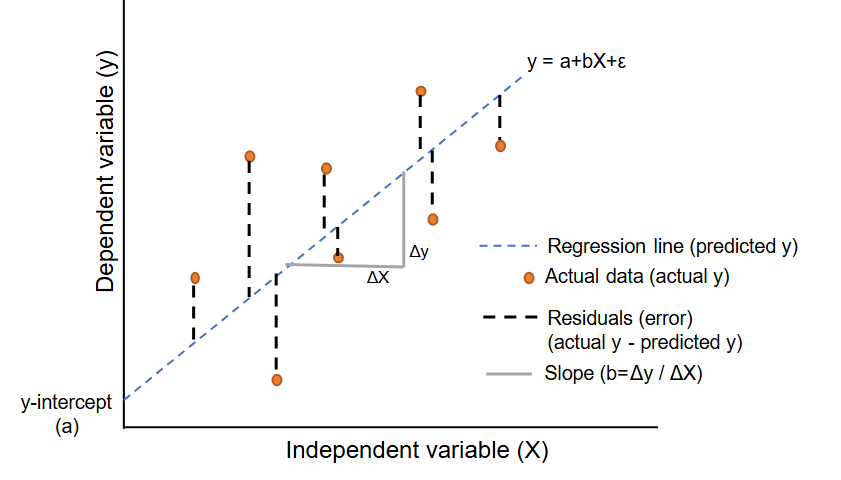

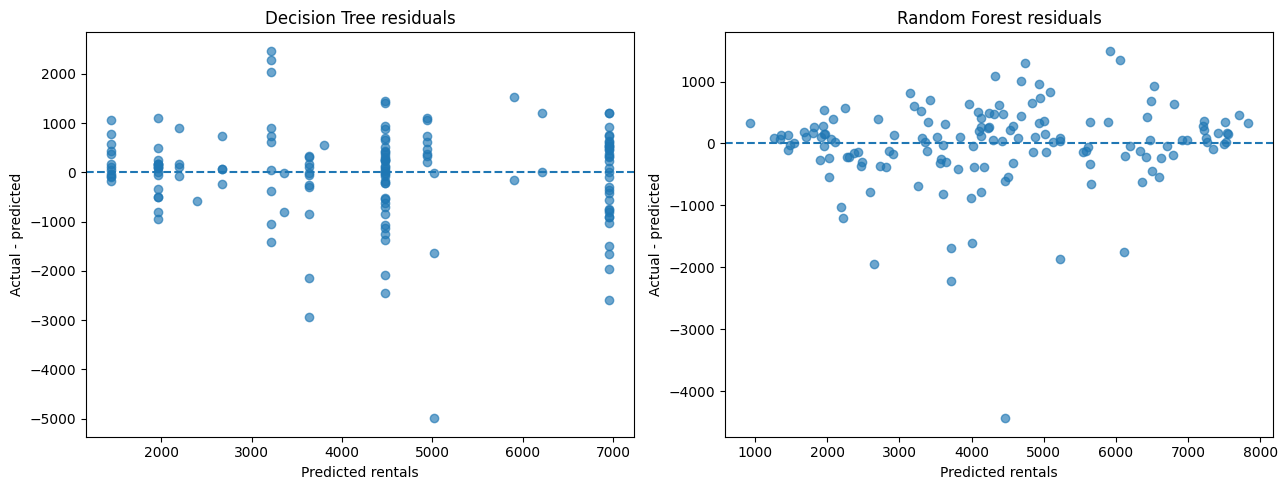

In [10]:
res_dt, res_rf = y_test-pred_dt, y_test-pred_rf
fig, axes = plt.subplots(1,2,figsize=(13,5))
for ax, pred, residual, title in [
    (axes[0],pred_dt,res_dt,"Decision Tree residuals"),
    (axes[1],pred_rf,res_rf,"Random Forest residuals")
]:
    ax.scatter(pred,residual,alpha=.65)
    ax.axhline(0,linestyle="--")
    ax.set_xlabel("Predicted rentals"); ax.set_ylabel("Actual - predicted")
    ax.set_title(title)
plt.tight_layout(); plt.show()

## 11. Feature importance

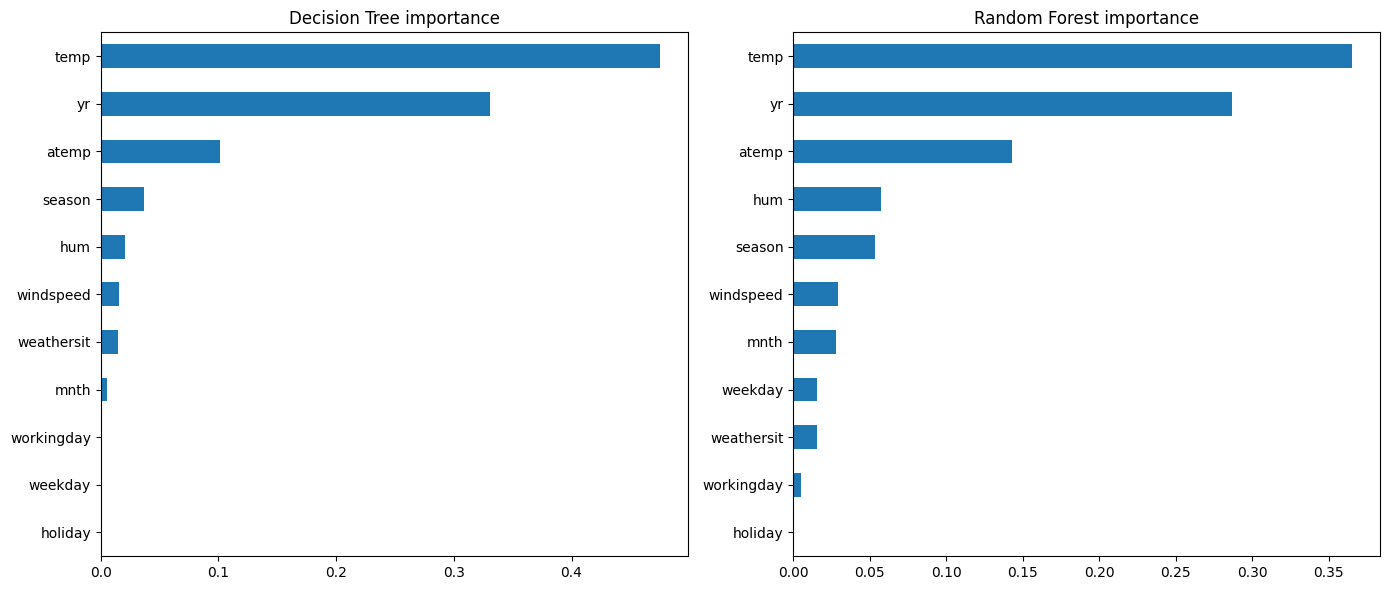

In [11]:
fig, axes = plt.subplots(1,2,figsize=(14,6))
pd.Series(dt.feature_importances_,index=features).sort_values().plot(
    kind="barh",ax=axes[0],title="Decision Tree importance")
pd.Series(rf.feature_importances_,index=features).sort_values().plot(
    kind="barh",ax=axes[1],title="Random Forest importance")
plt.tight_layout(); plt.show()

## 12. Hyperparameter experiment

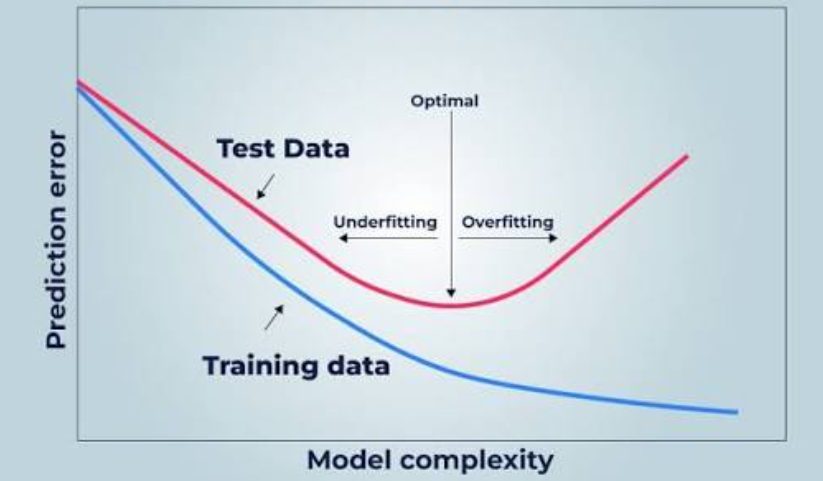

In [12]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

rows=[]
for depth in [3,5,8,None]:
    m=DecisionTreeRegressor(max_depth=depth,min_samples_leaf=5,random_state=42)
    m.fit(X_train,y_train)
    rows.append({"model":"Decision Tree","depth":str(depth),"trees":"-",
                 "train_R2":m.score(X_train,y_train),"test_R2":m.score(X_test,y_test)})

for n_trees in [50,100,300]:
    m=RandomForestRegressor(n_estimators=n_trees,max_features=1.0,
        min_samples_leaf=2,random_state=42,n_jobs=-1)
    m.fit(X_train,y_train)
    rows.append({"model":"Random Forest","depth":"None","trees":n_trees,
                 "train_R2":m.score(X_train,y_train),"test_R2":m.score(X_test,y_test)})

display(pd.DataFrame(rows).round(3))

,model,depth,trees,train_R2,test_R2
0,Decision Tree,3,-,0.774,0.693
1,Decision Tree,5,-,0.875,0.786
2,Decision Tree,8,-,0.918,0.798
3,Decision Tree,None,-,0.928,0.804
4,Random Forest,None,50,0.969,0.879
5,Random Forest,None,100,0.970,0.881
6,Random Forest,None,300,0.970,0.881


## 13. Predict demand for a sample day

In [13]:
new_day = pd.DataFrame([{
    "season":2,"yr":1,"mnth":6,"holiday":0,"weekday":2,
    "workingday":1,"weathersit":1,"temp":0.65,"atemp":0.62,
    "hum":0.55,"windspeed":0.15
}])
print("Decision Tree estimate: {:,.0f} bikes".format(dt.predict(new_day)[0]))
print("Random Forest estimate: {:,.0f} bikes".format(rf.predict(new_day)[0]))

Decision Tree estimate: 6,955 bikes
Random Forest estimate: 7,082 bikes


## 14. Classroom discussion and challenge
1. How is a regression tree different from a classification tree?
2. What does a leaf prediction represent?
3. What does a split such as `temp <= 0.42` mean?
4. Why can a deep tree overfit?
5. How does averaging trees help Random Forest?
6. Explain MAE, RMSE and R² in business language.
7. What is the operational cost of underpredicting bike demand versus overpredicting it?

**Challenge:** Tune `max_depth`, `min_samples_leaf`, `n_estimators` and `max_features`. Compare MAE, RMSE and R². Identify where each model makes its largest errors.

**Production note:** For real demand forecasting, prefer chronological validation, compare against a simple baseline, and monitor seasonal drift.

### Discussion Answers

#### 1. How is a regression tree different from a classification tree?
* **Target Variable:** A regression tree predicts a continuous/numerical value (e.g., the number of rented bikes), whereas a classification tree predicts a discrete categorical label (e.g., 'Yes' or 'No').
* **Split Criterion:** Regression trees typically use metrics like reduction in **Mean Squared Error (MSE)** or **Variance** to choose splits, while classification trees use **Gini Impurity** or **Entropy**.
* **Leaf Prediction:** In a regression tree, the prediction at each leaf is typically the **mean** (average) of the target values of the training samples in that leaf. In a classification tree, it is the **majority class** (mode).

#### 2. What does a leaf prediction represent?
* It represents the **average (mean) target value** of all training data points that fell into that specific leaf node. For example, if a leaf node contains 15 days with an average of 4,500 rentals, any new day that falls into this leaf will be predicted to have 4,500 rentals.

#### 3. What does a split such as `temp <= 0.42` mean?
* It is a decision boundary. If a day's normalized temperature is $0.42$ or lower, the model follows the **left branch** (True). If it is greater than $0.42$, the model follows the **right branch** (False). The algorithm selected $0.42$ because splitting the dataset at this exact point maximized the reduction in variance (impurity) of the target variable `cnt` between the parent group and the resulting children groups.

#### 4. Why can a deep tree overfit?
* A very deep tree can split the data until there are very few samples in each leaf node (potentially memorizing individual data points, including noise). This results in extremely low training error (high variance) but poor generalization performance on unseen test data.

#### 5. How does averaging trees help Random Forest?
* Random Forest is an **ensemble bagging** technique. Each individual decision tree is trained on a bootstrap sample of the data and a random subset of features, which makes the trees diverse and individually high-variance. By averaging their predictions, the random errors and high variances of individual trees cancel out, leading to a much more stable, robust, and generalizable model without increasing bias.

#### 6. Explain MAE, RMSE and R² in business language.
* **MAE (Mean Absolute Error):** "On average, our predictions are off by about $X$ bikes." It is easy to explain because it treats all errors linearly.
* **RMSE (Root Mean Squared Error):** "On average, our predictions are off by $Y$ bikes, but we penalize large mistakes much more severely." If being off by 2,000 bikes is significantly worse than being off by 1,000 bikes twice, RMSE is a better indicator of business risk.
* **R² (Coefficient of Determination):** "Our model explains $Z\%$ of the variation in daily bike rentals." A value of $1.0$ is a perfect model, while $0.0$ performs no better than predicting the global historical average rental count for every day.

#### 7. What is the operational cost of underpredicting bike demand versus overpredicting it?
* **Underpredicting (Predicting too low):** Leads to **lost revenue opportunities**, frustrated customers who cannot find a bike, and potential loss of customer loyalty to competitors.
* **Overpredicting (Predicting too high):** Leads to **excess operational costs** (unnecessary bike maintenance, relocation/rebalancing costs to move idle bikes, and wasted storage space).